# Modelo XGBoost — Fase 6, paso 3: elección del umbral de decisión

Este notebook elige el umbral de decisión del modelo que salió de `03_tuning.ipynb` (`learning_rate=0.3`, `max_depth=4`, `min_child_weight=1`), entrenado con el train real y 55 features, con `scale_pos_weight = benignos / ataques` calculado solo con `y_train` (variante C de `02b_ablacion_smote.ipynb`). XGBoost da una probabilidad de ataque por flujo, y el umbral es el valor a partir del cual esa probabilidad se clasifica como ataque. Hasta ahora todo se midió con 0.5.

Pasos:

1. Reentrenar el modelo elegido con la misma configuración que en `03_tuning.ipynb` y verificar que reproduce su resultado en val: best_iteration 68, FP 13 y FN 3 con umbral 0.5. Si no lo reproduce, el notebook se detiene.
2. Aplicar la regla de elección de umbral sobre val completo, y repetirla sobre 1,000 remuestreos bootstrap de val para ver qué tan estable es el umbral ganador.
3. Tomar como umbral final la mediana de los umbrales ganadores del bootstrap.

**La regla se definió antes de ver resultados.** Está escrita más abajo, en su propia celda, antes de la celda que la aplica, y no se ajustó después de ver ningún número de este notebook. Antes de ejecutarlo cambiaron dos cosas, explicadas en esa celda: la grilla de umbrales se extendió por debajo de 0.01 y, con el dataset corregido (443,614 filas), el objetivo de la regla pasó de F1 a F2 para usar el mismo criterio que SVM y GRU.

**Val elige el umbral; test queda reservado.** Val ya se usó en `03_tuning.ipynb` para el early stopping y para elegir la combinación de hiperparámetros, y acá se usa además para elegir el umbral. Por eso las métricas en val de este notebook son optimistas y no son una estimación del desempeño del modelo. `X_test` / `y_test` no se cargan en este notebook: se reservan para la evaluación final del modelo cerrado (hiperparámetros + umbral).

In [1]:
import sys
from pathlib import Path

# Raíz del repo = primera carpeta hacia arriba que contenga src/.
# Así el notebook funciona sin importar desde dónde se abra el kernel.
RAIZ_REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ_REPO) not in sys.path:
    sys.path.append(str(RAIZ_REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from src.evaluation.metrics import evaluate_model, Timer

DATA_DIR = RAIZ_REPO / "data" / "processed" / "xgboost"
print(f"Python:        {sys.executable}")
print(f"Raíz del repo: {RAIZ_REPO}")
print(f"Datos:         {DATA_DIR}")
print(f"xgboost {xgb.__version__}")

Python:        C:\Users\Andy Ortega\Progras\Proyecto de Graduación\low-and-slow-ids\venv\Scripts\python.exe
Raíz del repo: C:\Users\Andy Ortega\Progras\Proyecto de Graduación\low-and-slow-ids
Datos:         C:\Users\Andy Ortega\Progras\Proyecto de Graduación\low-and-slow-ids\data\processed\xgboost
xgboost 3.3.0


### Carga de train y val

Solo train y val, igual que en `03_tuning.ipynb`. Test no se carga.

Se verifica que `X_train.csv` sea el train real (310,529 filas y 8,230 ataques) y que la matriz tenga 55 features, sin `Destination Port`, `Source Port`, `Protocol` ni `Fwd PSH Flags`, y sin las columnas de metadatos del split (`Timestamp`, `bloque`). `scale_pos_weight` se calcula como benignos / ataques de `y_train`, igual que en `03_tuning.ipynb`.

In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")["label_binaria"].to_numpy()
X_val = pd.read_csv(DATA_DIR / "X_val.csv")
y_val = pd.read_csv(DATA_DIR / "y_val.csv")["label_binaria"].to_numpy()

assert list(X_train.columns) == list(X_val.columns), "Columnas distintas entre train y val"
N_TRAIN_ESPERADO = 310_529
N_ATAQUES_TRAIN_ESPERADO = 8_230
assert len(X_train) == N_TRAIN_ESPERADO, f"Se esperaban {N_TRAIN_ESPERADO:,} filas en el train real, hay {len(X_train):,}"
assert y_train.sum() == N_ATAQUES_TRAIN_ESPERADO, (
    f"Se esperaban {N_ATAQUES_TRAIN_ESPERADO:,} ataques en el train real, hay {y_train.sum():,}"
)

N_FEATURES_ESPERADO = 55
assert X_train.shape[1] == N_FEATURES_ESPERADO, f"Se esperaban {N_FEATURES_ESPERADO} features, hay {X_train.shape[1]}"

COLUMNAS_EXCLUIDAS = ["Destination Port", "Source Port", "Protocol", "Fwd PSH Flags", "Timestamp", "bloque"]
presentes = [c for c in COLUMNAS_EXCLUIDAS if c in X_train.columns]
assert not presentes, f"Columnas que no deberían estar en X_train/X_val: {presentes}"

for nombre, X, y in [("train", X_train, y_train), ("val", X_val, y_val)]:
    print(f"{nombre:>5}: X {X.shape} | y {y.shape} | ataques: {y.sum()} ({y.mean():.4%})")

# scale_pos_weight = benignos / ataques, calculado solo con y_train (variante C de 02b).
n_benignos_train = int((y_train == 0).sum())
n_ataques_train = int(y_train.sum())
SCALE_POS_WEIGHT = n_benignos_train / n_ataques_train
print(f"\nscale_pos_weight = {n_benignos_train:,} / {n_ataques_train:,} = {SCALE_POS_WEIGHT:.4f}")

train: X (310529, 55) | y (310529,) | ataques: 8230 (2.6503%)
  val: X (66541, 55) | y (66541,) | ataques: 1884 (2.8313%)

scale_pos_weight = 302,299 / 8,230 = 36.7313


### Reentrenamiento del modelo elegido y verificación contra `03_tuning.ipynb`

Misma configuración que la combinación elegida en `03_tuning.ipynb`: `learning_rate=0.3`, `max_depth=4`, `min_child_weight=1`, `n_estimators=1000`, `early_stopping_rounds=50`, `eval_metric="aucpr"`, `tree_method="hist"`, `random_state=42` y `scale_pos_weight=SCALE_POS_WEIGHT` (calculado arriba desde `y_train`). Se entrena en GPU (`device="cuda"`), igual que en 03. Antes de predecir se pasa a CPU con `set_params(device="cpu")`, porque `X_val` está en memoria de CPU.

Con umbral 0.5 tiene que dar best_iteration 68, FP 13 y FN 3. Si no, el notebook se detiene acá: elegir un umbral sobre un modelo distinto del que se eligió en 03 no tendría sentido.

Las probabilidades se pasan a `float64` para que todas las comparaciones contra los umbrales de la grilla (0.001, 0.002, …, 0.01, 0.02, …) usen el mismo valor de cada umbral. Con 0.5 no cambia nada, porque 0.5 es exacto en `float32`.

In [3]:
# Combinación elegida en 03_tuning.ipynb (dataset corregido, 443,614 filas)
PARAMS = {
    "learning_rate": 0.3,
    "max_depth": 4,
    "min_child_weight": 1,
    "n_estimators": 1000,
    "early_stopping_rounds": 50,
    "eval_metric": "aucpr",
    "tree_method": "hist",
    "device": "cuda",
    "random_state": 42,
    "n_jobs": -1,
    "scale_pos_weight": SCALE_POS_WEIGHT,
}
REFERENCIA_03 = {"best_iteration": 68, "FP": 13, "FN": 3}

modelo = xgb.XGBClassifier(**PARAMS)
with Timer() as t:
    modelo.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
tiempo_entrenamiento = t.elapsed
modelo.set_params(device="cpu")

proba_val = modelo.predict_proba(X_val)[:, 1].astype(np.float64)

tn_05, fp_05, fn_05, tp_05 = confusion_matrix(y_val, (proba_val >= 0.5).astype(int), labels=[0, 1]).ravel()
obtenido = {"best_iteration": int(modelo.best_iteration), "FP": int(fp_05), "FN": int(fn_05)}
print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.2f}s")
print(f"Esperado (03_tuning): {REFERENCIA_03}")
print(f"Obtenido:             {obtenido}")

if obtenido != REFERENCIA_03:
    raise RuntimeError(
        "NO REPRODUCE 03_tuning.ipynb: el modelo reentrenado no coincide con el elegido. "
        "Se detiene el notebook sin elegir umbral."
    )
print("Reproduce 03_tuning.ipynb.")

Tiempo de entrenamiento: 0.90s
Esperado (03_tuning): {'best_iteration': 68, 'FP': 13, 'FN': 3}
Obtenido:             {'best_iteration': 68, 'FP': 13, 'FN': 3}
Reproduce 03_tuning.ipynb.


### Regla de elección del umbral

Definida antes de ver resultados:

- **(a) Búsqueda en val.** Umbrales de 0.001 a 0.009 en pasos de 0.001 y de 0.01 a 0.99 en pasos de 0.01 (9 + 99 = 108 valores). Un flujo se clasifica como ataque si su probabilidad es >= al umbral. Entre los umbrales con recall >= 0.75 en val, se elige el de mayor F2 (F-beta con beta = 2, que le da al recall cuatro veces el peso de la precision). Si hay empate en F2, el umbral más alto.
- **(b) Bootstrap.** 1,000 remuestreos de val con reemplazo, estratificados por clase (cada remuestreo tiene la misma cantidad de benignos y de ataques que val: 64,657 y 1,884), con semilla fija 42. En cada remuestreo se aplica la regla (a) y se guarda el umbral ganador.
- **(c) Umbral final** = mediana de los 1,000 umbrales ganadores, con `np.median`. Como 1,000 es par, la mediana es el promedio de los valores 500 y 501 ordenados, así que puede quedar entre dos puntos de la grilla; en ese caso se usa tal cual.

La grilla se extendió por debajo de 0.01 (0.001 a 0.009) antes de ejecutar este notebook con el modelo actual, porque en un análisis previo el mejor umbral cayó en el borde de la grilla (0.01).

**Cambio deliberado: F1 → F2.** Hasta la corrida sobre el dataset original, (a) maximizaba F1. Antes de ejecutar este notebook sobre el dataset corregido (443,614 filas), el objetivo se cambió a F2, para que XGBoost use el mismo criterio que SVM y GRU (mayor F2 con recall >= 0.75). Es el único cambio: la grilla, el piso de recall, el desempate y el bootstrap son los mismos. F1, precision, recall, FP y FN se siguen reportando. Como registro, se informa también qué umbral habría dado la regla anterior (mayor F1) en val completo y en los mismos 1,000 remuestreos; ese umbral no interviene en la elección.

El modelo no se reentrena dentro del bootstrap: se remuestrean las probabilidades que ya dio sobre val. El bootstrap mide cuánto cambiaría el umbral elegido si val hubiera tenido otros flujos de la misma distribución, no la variabilidad del entrenamiento.

Detalles de implementación, que no cambian la regla:

- recall >= 0.75 se evalúa con enteros (`4·TP >= 3·(TP + FN)`) y F2 como `5·TP / (5·TP + 4·FN + FP)` (F1, para el registro, como `2·TP / (2·TP + FN + FP)`): numerador y denominador son enteros y hay una sola división, así que los empates son exactos y no dependen del redondeo de punto flotante.
- Para que el bootstrap sea rápido, a cada flujo se le asigna un *tramo*: cuántos umbrales de la grilla alcanza su probabilidad. El flujo se predice como ataque en el umbral *j* si y solo si su tramo es mayor que *j*, así que TP y FP de los 108 umbrales salen de sumas acumuladas por tramo. Para eso la grilla tiene que estar ordenada de menor a mayor (`np.searchsorted`), y se verifica. Remuestrear flujos es lo mismo que remuestrear sus tramos. Más abajo se verifica que da lo mismo que calcular la matriz de confusión umbral por umbral.
- Si en algún remuestreo ningún umbral cumple recall >= 0.75, la regla no dice qué hacer. En ese caso el notebook se detiene y lo reporta en vez de inventar un criterio.

In [4]:
# Cada parte de la grilla se redondea con sus propios decimales: con 2 decimales, 0.001–0.009 quedarían en 0.00 y 0.01.
UMBRALES = np.concatenate([
    np.round(np.arange(1, 10) / 1000, 3),  # 0.001 a 0.009
    np.round(np.arange(1, 100) / 100, 2),  # 0.01 a 0.99
])
assert len(UMBRALES) == 108, f"Se esperaban 108 umbrales, hay {len(UMBRALES)}"
assert np.all(np.diff(UMBRALES) > 0), "La grilla tiene que estar estrictamente ordenada para np.searchsorted"
N_BOOTSTRAP = 1000
SEMILLA = 42
BETA2_REGLA = 4     # F2: beta = 2 (objetivo de la regla)
BETA2_REGISTRO = 1  # F1: objetivo de la regla anterior, solo como registro

es_ataque = y_val == 1
# Tramo de cada flujo = cuántos umbrales de la grilla cumplen proba >= umbral.
tramo_val = np.searchsorted(UMBRALES, proba_val, side="right")
tramo_ataques = tramo_val[es_ataque]
tramo_benignos = tramo_val[~es_ataque]


def conteos(tramos_ataques: np.ndarray, tramos_benignos: np.ndarray):
    """TP, FP y FN en cada umbral de la grilla, a partir de los tramos de ataques y benignos."""
    no_positivos_ataques = np.cumsum(np.bincount(tramos_ataques, minlength=len(UMBRALES) + 1))[:-1]
    no_positivos_benignos = np.cumsum(np.bincount(tramos_benignos, minlength=len(UMBRALES) + 1))[:-1]
    tp = len(tramos_ataques) - no_positivos_ataques
    fp = len(tramos_benignos) - no_positivos_benignos
    fn = len(tramos_ataques) - tp
    return tp, fp, fn


def f_beta(tp, fp, fn, beta2: int):
    """F-beta con beta² entero: (1 + β²)·TP / ((1 + β²)·TP + β²·FN + FP). beta2=4 da F2; beta2=1, F1."""
    return (1 + beta2) * tp / ((1 + beta2) * tp + beta2 * fn + fp)


def aplicar_regla(tp: np.ndarray, fp: np.ndarray, fn: np.ndarray, beta2: int = BETA2_REGLA) -> float:
    """Regla (a): mayor F2 entre los umbrales con recall >= 0.75; si hay empate, el umbral más alto.

    Con beta2=BETA2_REGISTRO da la regla anterior (mayor F1), que solo se reporta como registro.
    """
    elegibles = 4 * tp >= 3 * (tp + fn)
    if not elegibles.any():
        return np.nan
    f = np.where(elegibles, f_beta(tp, fp, fn, beta2), -np.inf)
    return float(UMBRALES[np.flatnonzero(f == f.max()).max()])


# Verificación: los conteos por tramo coinciden con la matriz de confusión umbral por umbral.
tp_val, fp_val, fn_val = conteos(tramo_ataques, tramo_benignos)
for j, umbral in enumerate(UMBRALES):
    tn, fp, fn, tp = confusion_matrix(y_val, (proba_val >= umbral).astype(int), labels=[0, 1]).ravel()
    assert (tp, fp, fn) == (tp_val[j], fp_val[j], fn_val[j]), f"Conteos distintos en umbral {umbral}"
print(f"Conteos por tramo verificados en los {len(UMBRALES)} umbrales.")

curva = pd.DataFrame({
    "umbral": UMBRALES,
    "precision": np.divide(tp_val, tp_val + fp_val, out=np.zeros(len(UMBRALES)), where=(tp_val + fp_val) > 0),
    "recall": tp_val / (tp_val + fn_val),
    "f1": f_beta(tp_val, fp_val, fn_val, BETA2_REGISTRO),
    "f2": f_beta(tp_val, fp_val, fn_val, BETA2_REGLA),
    "FP": fp_val,
    "FN": fn_val,
    "cumple_recall": 4 * tp_val >= 3 * (tp_val + fn_val),
})

Conteos por tramo verificados en los 108 umbrales.


### (a) Umbral ganador en val completo

In [5]:
def metricas_umbral(umbral: float) -> dict:
    """Precision, recall, F1, F2 y matriz de confusión en val para un umbral (dentro o fuera de la grilla)."""
    tn, fp, fn, tp = confusion_matrix(y_val, (proba_val >= umbral).astype(int), labels=[0, 1]).ravel()
    return {
        "precision": tp / (tp + fp) if (tp + fp) > 0 else 0.0,
        "recall": tp / (tp + fn),
        "f1": f_beta(tp, fp, fn, BETA2_REGISTRO),
        "f2": f_beta(tp, fp, fn, BETA2_REGLA),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn),
    }


UMBRAL_A = aplicar_regla(tp_val, fp_val, fn_val)
m_a = metricas_umbral(UMBRAL_A)
# Registro: lo que habría elegido la regla anterior (mayor F1) en val completo. No interviene en la elección.
UMBRAL_A_F1 = aplicar_regla(tp_val, fp_val, fn_val, beta2=BETA2_REGISTRO)

elegibles_val = curva[curva["cumple_recall"]]
empatados = elegibles_val.loc[elegibles_val["f2"] == elegibles_val["f2"].max(), "umbral"].tolist()

print(f"Umbrales que cumplen recall >= 0.75: {len(elegibles_val)} de {len(UMBRALES)}")
print(f"Umbrales empatados en el F2 máximo:  {empatados}")
print(f"Umbral ganador (a):                  {UMBRAL_A:g}\n")
print(f"precision {m_a['precision']:.6f} | recall {m_a['recall']:.6f} | F2 {m_a['f2']:.6f} | F1 {m_a['f1']:.6f}")
print(f"TN {m_a['TN']} | FP {m_a['FP']} | FN {m_a['FN']} | TP {m_a['TP']}")
print(f"\nRegistro, regla anterior (mayor F1) en val completo: {UMBRAL_A_F1:g}")

print("\n10 umbrales elegibles con mayor F2 (contexto, no cambia la elección):")
with pd.option_context("display.float_format", "{:.6f}".format, "display.width", 200):
    print(elegibles_val.sort_values(["f2", "umbral"], ascending=[False, False])
          .head(10).drop(columns="cumple_recall").to_string(index=False))

Umbrales que cumplen recall >= 0.75: 108 de 108
Umbrales empatados en el F2 máximo:  [0.19, 0.2]
Umbral ganador (a):                  0.2

precision 0.992093 | recall 0.998938 | F2 0.997562 | F1 0.995504
TN 64642 | FP 15 | FN 2 | TP 1882

Registro, regla anterior (mayor F1) en val completo: 0.87

10 umbrales elegibles con mayor F2 (contexto, no cambia la elección):
  umbral  precision   recall       f1       f2  FP  FN
0.200000   0.992093 0.998938 0.995504 0.997562  15   2
0.190000   0.992093 0.998938 0.995504 0.997562  15   2
0.870000   0.994186 0.998408 0.996292 0.997560  11   3
0.860000   0.994186 0.998408 0.996292 0.997560  11   3
0.850000   0.994186 0.998408 0.996292 0.997560  11   3
0.840000   0.994186 0.998408 0.996292 0.997560  11   3
0.830000   0.994186 0.998408 0.996292 0.997560  11   3
0.820000   0.994186 0.998408 0.996292 0.997560  11   3
0.810000   0.994186 0.998408 0.996292 0.997560  11   3
0.800000   0.993661 0.998408 0.996029 0.997455  12   3


### (b) Bootstrap: 1,000 remuestreos estratificados de val

Un solo generador (`np.random.default_rng(42)`). En cada remuestreo se sortean primero los benignos y después los ataques, cada clase con reemplazo y con su tamaño original. Sobre cada remuestreo se aplica también, como registro, la regla anterior (mayor F1); eso no sortea nada, así que los remuestreos son los mismos que si no se aplicara.

In [6]:
rng = np.random.default_rng(SEMILLA)
ganadores = np.empty(N_BOOTSTRAP)
ganadores_f1 = np.empty(N_BOOTSTRAP)  # registro: regla anterior (mayor F1) sobre los mismos remuestreos
for b in range(N_BOOTSTRAP):
    muestra_benignos = tramo_benignos[rng.integers(0, len(tramo_benignos), size=len(tramo_benignos))]
    muestra_ataques = tramo_ataques[rng.integers(0, len(tramo_ataques), size=len(tramo_ataques))]
    tp_b, fp_b, fn_b = conteos(muestra_ataques, muestra_benignos)
    ganadores[b] = aplicar_regla(tp_b, fp_b, fn_b)
    ganadores_f1[b] = aplicar_regla(tp_b, fp_b, fn_b, beta2=BETA2_REGISTRO)

sin_elegible = int(np.isnan(ganadores).sum())
print(f"Remuestreos: {N_BOOTSTRAP} | sin ningún umbral con recall >= 0.75: {sin_elegible}")
if sin_elegible:
    raise RuntimeError(
        f"En {sin_elegible} remuestreos ningún umbral cumple recall >= 0.75. "
        "La regla no define qué hacer en ese caso; se detiene el notebook."
    )

# (c) Umbral final = mediana de los umbrales ganadores.
UMBRAL_FINAL = float(np.median(ganadores))
print(f"Umbral final (mediana): {UMBRAL_FINAL}")

# Registro: umbral final que habría dado la regla anterior (mayor F1). No interviene en la elección.
UMBRAL_FINAL_F1 = float(np.median(ganadores_f1))
print(f"Registro, regla anterior (mayor F1), mediana: {UMBRAL_FINAL_F1}")

Remuestreos: 1000 | sin ningún umbral con recall >= 0.75: 0
Umbral final (mediana): 0.87
Registro, regla anterior (mayor F1), mediana: 0.87


### Distribución de los umbrales ganadores del bootstrap

Percentiles con `np.percentile` (interpolación lineal, la opción por defecto). El percentil 50 es la misma mediana de (c). Los percentiles 2.5 y 97.5 encierran el 95 % central de los umbrales ganadores.

In [7]:
PERCENTILES = {"mínimo": 0, "p2.5": 2.5, "p5": 5, "p25": 25, "mediana": 50, "p75": 75, "p95": 95, "p97.5": 97.5,
               "máximo": 100}
distribucion = pd.Series({nombre: np.percentile(ganadores, q) for nombre, q in PERCENTILES.items()},
                         name="umbral")
print(distribucion.to_frame().T.to_string(index=False, float_format="{:g}".format))

frecuencias = pd.Series(ganadores).value_counts().sort_index()
tabla_frecuencias = pd.DataFrame({
    "veces_ganador": frecuencias,
    "proporcion": frecuencias / N_BOOTSTRAP,
    "acumulada": frecuencias.cumsum() / N_BOOTSTRAP,
})
tabla_frecuencias.index = [f"{u:g}" for u in tabla_frecuencias.index]
tabla_frecuencias.index.name = "umbral"
print(f"\nFrecuencia de cada umbral ganador ({len(frecuencias)} valores distintos):")
print(tabla_frecuencias.to_string(float_format="{:.3f}".format))

distribucion_f1 = pd.Series({nombre: np.percentile(ganadores_f1, q) for nombre, q in PERCENTILES.items()},
                            name="umbral")
print("\nRegistro, regla anterior (mayor F1), mismos remuestreos:")
print(distribucion_f1.to_frame().T.to_string(index=False, float_format="{:g}".format))

 mínimo  p2.5  p5  p25  mediana  p75  p95  p97.5  máximo
    0.2   0.2 0.2  0.2     0.87 0.87 0.87   0.87    0.91

Frecuencia de cada umbral ganador (3 valores distintos):
        veces_ganador  proporcion  acumulada
umbral                                      
0.2               494       0.494      0.494
0.87              503       0.503      0.997
0.91                3       0.003      1.000

Registro, regla anterior (mayor F1), mismos remuestreos:
 mínimo  p2.5  p5  p25  mediana  p75  p95  p97.5  máximo
    0.2   0.2 0.2 0.87     0.87 0.87 0.87   0.87    0.91


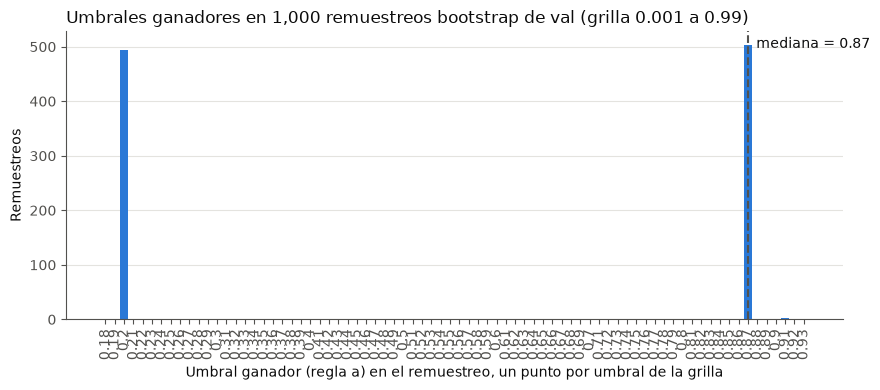

In [8]:
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # paleta categórica: series 1, 2 y 3
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"


def estilo_ejes(ax):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(TINTA_SUAVE)
    ax.tick_params(colors=TINTA_SUAVE)
    ax.grid(axis="y", color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)


fig, ax = plt.subplots(figsize=(9, 4))
# La grilla no tiene paso uniforme (0.001 por debajo de 0.01, 0.01 desde ahí), así que el eje x va por posición
# en la grilla: una barra por umbral, con hasta dos puntos de margen a cada lado del rango observado.
posicion_ganadores = np.searchsorted(UMBRALES, ganadores)
assert np.array_equal(UMBRALES[posicion_ganadores], ganadores), "Hay umbrales ganadores fuera de la grilla"
posiciones = np.arange(max(posicion_ganadores.min() - 2, 0), min(posicion_ganadores.max() + 2, len(UMBRALES) - 1) + 1)
alturas = np.bincount(posicion_ganadores - posiciones[0], minlength=len(posiciones))
ax.bar(posiciones, alturas, width=0.85, color=AZUL)
ax.set_xticks(posiciones, [f"{u:g}" for u in UMBRALES[posiciones]], rotation=90 if len(posiciones) > 15 else 0)
# La mediana puede caer entre dos puntos de la grilla: su posición se interpola entre ellos.
x_mediana = np.interp(UMBRAL_FINAL, UMBRALES, np.arange(len(UMBRALES)))
ax.axvline(x_mediana, color=TINTA_SUAVE, linestyle="--", linewidth=1.5)
ax.annotate(f"mediana = {UMBRAL_FINAL:g}", xy=(x_mediana, 1), xycoords=("data", "axes fraction"),
            xytext=(6, -4), textcoords="offset points", va="top", color=TINTA)
ax.set_xlabel("Umbral ganador (regla a) en el remuestreo, un punto por umbral de la grilla", color=TINTA)
ax.set_ylabel("Remuestreos", color=TINTA)
ax.set_title(f"Umbrales ganadores en {N_BOOTSTRAP:,} remuestreos bootstrap de val (grilla 0.001 a 0.99)",
             color=TINTA, loc="left")
estilo_ejes(ax)
plt.tight_layout()
plt.show()

### (c) Umbral final en val

`evaluate_model` con `save_dir=None`: no escribe `reports/metrics/`, porque esto es val (usado para elegir el umbral), no la evaluación final en test. ROC-AUC no depende del umbral, así que es el mismo que en `03_tuning.ipynb`. F2 se imprime aparte, porque `evaluate_model` todavía no lo calcula.


=== Resultados: xgboost_umbral_0.87_val ===
Accuracy:  0.9998
Precision: 0.9942
Recall:    0.9984  <- métrica principal
F1-score:  0.9963
ROC-AUC:   1.0000
Matriz de confusión -> TN: 64646, FP: 11, FN: 3, TP: 1881
Tiempo de entrenamiento: 0.90s

Matriz de confusión en val, umbral 0.87:
predicho  benigno  ataque
real                     
benigno     64646      11
ataque          3    1881

F2 (beta = 2) en val, umbral 0.87: 0.997560


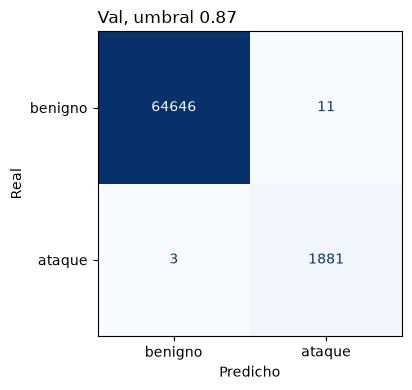

In [9]:
y_pred_final = (proba_val >= UMBRAL_FINAL).astype(int)
resultados_final = evaluate_model(
    y_val,
    y_pred_final,
    y_proba=proba_val,
    model_name=f"xgboost_umbral_{UMBRAL_FINAL:g}_val",
    training_time_seconds=tiempo_entrenamiento,
    save_dir=None,
)

mc = resultados_final["matriz_confusion"]
matriz_final = pd.DataFrame(
    [[mc["verdaderos_negativos"], mc["falsos_positivos"]],
     [mc["falsos_negativos"], mc["verdaderos_positivos"]]],
    index=pd.Index(["benigno", "ataque"], name="real"),
    columns=pd.Index(["benigno", "ataque"], name="predicho"),
)
print(f"\nMatriz de confusión en val, umbral {UMBRAL_FINAL:g}:")
print(matriz_final.to_string())
print(f"\nF2 (beta = 2) en val, umbral {UMBRAL_FINAL:g}: {metricas_umbral(UMBRAL_FINAL)['f2']:.6f}")

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(matriz_final.to_numpy(), display_labels=["benigno", "ataque"]).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_title(f"Val, umbral {UMBRAL_FINAL:g}", loc="left")
plt.tight_layout()
plt.show()

### Comparación en val: umbral 0.5, ganador de (a), umbral final y registro de la regla anterior

La última columna es solo un registro: el umbral final (mediana del bootstrap) que habría dado la regla anterior, de mayor F1, con los mismos remuestreos. No interviene en la elección.

In [10]:
comparacion = pd.DataFrame({
    "umbral 0.5": metricas_umbral(0.5),
    f"ganador (a) = {UMBRAL_A:g}": m_a,
    f"final (mediana) = {UMBRAL_FINAL:g}": metricas_umbral(UMBRAL_FINAL),
    f"registro F1 (mediana) = {UMBRAL_FINAL_F1:g}": metricas_umbral(UMBRAL_FINAL_F1),
}).loc[["precision", "recall", "f2", "f1", "FP", "FN"]]

with pd.option_context("display.float_format", "{:.6f}".format, "display.width", 200):
    print(comparacion.to_string())

           umbral 0.5  ganador (a) = 0.2  final (mediana) = 0.87  registro F1 (mediana) = 0.87
precision    0.993136           0.992093                0.994186                      0.994186
recall       0.998408           0.998938                0.998408                      0.998408
f2           0.997349           0.997562                0.997560                      0.997560
f1           0.995765           0.995504                0.996292                      0.996292
FP          13.000000          15.000000               11.000000                     11.000000
FN           3.000000           2.000000                3.000000                      3.000000


### F2, F1 y recall en función del umbral (val completo)

F2 es el objetivo de la regla; F1 se muestra como referencia. La línea vertical marca el umbral final; la horizontal punteada, el recall mínimo de la regla (0.75), si cae dentro del rango del gráfico. El eje x está en escala logarítmica para que se vean tanto los umbrales de 0.001 a 0.009 como los de 0.01 a 0.99.

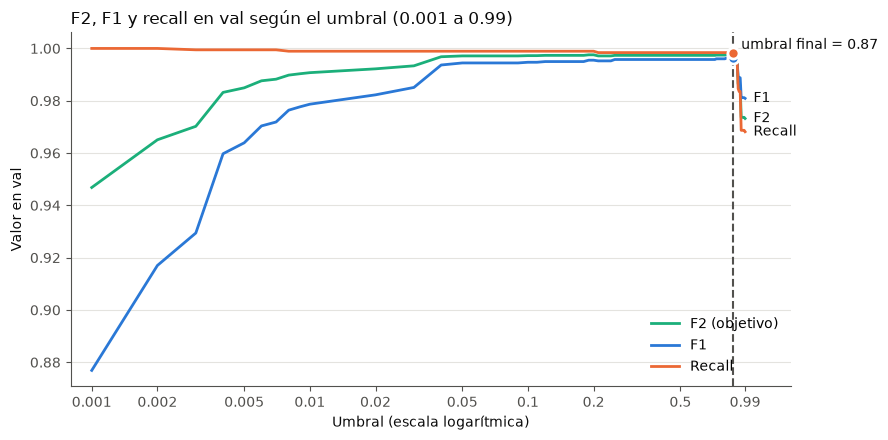

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curva["umbral"], curva["f2"], color=AQUA, linewidth=2, label="F2 (objetivo)")
ax.plot(curva["umbral"], curva["f1"], color=AZUL, linewidth=2, label="F1")
ax.plot(curva["umbral"], curva["recall"], color=NARANJA, linewidth=2, label="Recall")
for columna, color in [("f2", AQUA), ("f1", AZUL), ("recall", NARANJA)]:
    ax.annotate({"f2": "F2", "f1": "F1", "recall": "Recall"}[columna], xy=(curva["umbral"].iloc[-1], curva[columna].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=TINTA)

ymin, ymax = ax.get_ylim()
if ymin <= 0.75:
    ax.axhline(0.75, color=TINTA_SUAVE, linestyle=":", linewidth=1.2)
ax.axvline(UMBRAL_FINAL, color=TINTA_SUAVE, linestyle="--", linewidth=1.5)
m_final = metricas_umbral(UMBRAL_FINAL)
for valor, color in [(m_final["f2"], AQUA), (m_final["f1"], AZUL), (m_final["recall"], NARANJA)]:
    ax.plot(UMBRAL_FINAL, valor, "o", markersize=8, color=color, markeredgecolor="white", markeredgewidth=2)
ax.annotate(f"umbral final = {UMBRAL_FINAL:g}", xy=(UMBRAL_FINAL, 1), xycoords=("data", "axes fraction"),
            xytext=(6, -4), textcoords="offset points", va="top", color=TINTA)

ax.set_xscale("log")
MARCAS_X = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 0.99]
ax.set_xticks(MARCAS_X, [f"{u:g}" for u in MARCAS_X])
ax.minorticks_off()
ax.set_xlim(UMBRALES[0] * 0.8, 1.6)
ax.set_xlabel("Umbral (escala logarítmica)", color=TINTA)
ax.set_ylabel("Valor en val", color=TINTA)
ax.set_title("F2, F1 y recall en val según el umbral (0.001 a 0.99)", color=TINTA, loc="left")
ax.legend(loc="lower right", frameon=False)
estilo_ejes(ax)
plt.tight_layout()
plt.show()

### Resumen

In [12]:
print("=" * 64)
print("RESUMEN — Fase 6, paso 3: umbral de decisión XGBoost (solo val)")
print("=" * 64)
print(f"Modelo:                 lr {PARAMS['learning_rate']} | max_depth {PARAMS['max_depth']} | "
      f"min_child_weight {PARAMS['min_child_weight']} | best_iteration {modelo.best_iteration}")
print(f"scale_pos_weight:       {SCALE_POS_WEIGHT:.4f} (benignos / ataques de y_train)")
print(f"Reproduce 03_tuning:    sí (best_iteration {obtenido['best_iteration']}, FP {obtenido['FP']}, FN {obtenido['FN']})")
print(f"Regla:                  recall >= 0.75, mayor F2, empate -> umbral más alto | "
      f"grilla de {len(UMBRALES)} umbrales ({UMBRALES[0]:g} a {UMBRALES[-1]:g})")
print(f"(a) ganador en val:     {UMBRAL_A:g}")
print(f"(b) bootstrap:          {N_BOOTSTRAP} remuestreos, semilla {SEMILLA}, "
      f"p2.5 {distribucion['p2.5']:g} | p97.5 {distribucion['p97.5']:g} | rango [{distribucion['mínimo']:g}, {distribucion['máximo']:g}]")
print(f"(c) umbral final:       {UMBRAL_FINAL:g}")
for nombre in comparacion.columns:
    fila = comparacion[nombre]
    print(f"  {nombre:<32} precision {fila['precision']:.4f} | recall {fila['recall']:.4f} | "
          f"F2 {fila['f2']:.4f} | F1 {fila['f1']:.4f} | FP {int(fila['FP'])} | FN {int(fila['FN'])}")
print(f"Registro, regla anterior (mayor F1): (a) {UMBRAL_A_F1:g} | (c) mediana {UMBRAL_FINAL_F1:g} | "
      f"p2.5 {distribucion_f1['p2.5']:g} | p97.5 {distribucion_f1['p97.5']:g}")
print("Test: no se cargó. Se reserva para la evaluación final del modelo cerrado.")

RESUMEN — Fase 6, paso 3: umbral de decisión XGBoost (solo val)
Modelo:                 lr 0.3 | max_depth 4 | min_child_weight 1 | best_iteration 68
scale_pos_weight:       36.7313 (benignos / ataques de y_train)
Reproduce 03_tuning:    sí (best_iteration 68, FP 13, FN 3)
Regla:                  recall >= 0.75, mayor F2, empate -> umbral más alto | grilla de 108 umbrales (0.001 a 0.99)
(a) ganador en val:     0.2
(b) bootstrap:          1000 remuestreos, semilla 42, p2.5 0.2 | p97.5 0.87 | rango [0.2, 0.91]
(c) umbral final:       0.87
  umbral 0.5                       precision 0.9931 | recall 0.9984 | F2 0.9973 | F1 0.9958 | FP 13 | FN 3
  ganador (a) = 0.2                precision 0.9921 | recall 0.9989 | F2 0.9976 | F1 0.9955 | FP 15 | FN 2
  final (mediana) = 0.87           precision 0.9942 | recall 0.9984 | F2 0.9976 | F1 0.9963 | FP 11 | FN 3
  registro F1 (mediana) = 0.87     precision 0.9942 | recall 0.9984 | F2 0.9976 | F1 0.9963 | FP 11 | FN 3
Registro, regla anterior (may